In [3]:
!pip install pulser pulser-simulation networkx matplotlib numpy

In [106]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pulser import Register, Pulse, DigitalAnalogDevice, Sequence
from pulser_simulation import QutipBackend
from math import log2

# Question 1

In [42]:
pentagons_coordinates = np.array([
[ 1.3143277805,
-4.0450849720],
[ 4.2532540420, 0.0],
[ 1.3143277805, 4.0450849720],
[ -3.4409548010, 2.5],
[ -3.4409548010,
-2.5],
[ -8.1962373825,
-4.0450849720],
[-11.1351636440, 0.0],
 [ -8.1962373825, 4.0450849720]
])

pentagons_edges = [(0,1), (1,2), (2,3), (3,4),(4,0), (4,5),  (5,6), (6,7),(3,7)]
square_edges = [(0,1), (0, 2), (0, 6), (2,4), (4,6), (1,7), (1,3), (3,5), (7,5)]

squares_coordinates = np.array([
[ 3.5355339060, 0.0],
[ 8.5355339060, 0.0],
[ 0.0, 3.5355339060],
[12.0710678120,
-3.5355339060],
[-3.5355339060, 0.0],
[15.6066017180, 0.0],
[ 0.0,
-3.5355339060],
[12.0710678120, 3.5355339060]
])

G_pentagones = nx.Graph()
for i, o in enumerate(pentagons_coordinates):
  G_pentagones.add_node(i, pos=o)
G_pentagones.add_edges_from(pentagons_edges)


G_square = nx.Graph()
for i, o in enumerate(squares_coordinates):
  G_square.add_node(i, pos=o)
G_square.add_edges_from(square_edges)

#nx.draw(G_pentagones, pos=nx.get_node_attributes(G_pentagones, 'pos'), with_labels=True)
#nx.draw(G_square, pos=nx.get_node_attributes(G_square, 'pos'), with_labels=True)


print(nx.is_isomorphic(G_pentagones, G_square))

False


# Question 2

Ici les deux graphes bien qu'ils aient le même nombre de nodes et de edges ne sont pas isomorphiques car ont a pas assez d'informations pour affirmer que pour passer du graphe pentagone vers le carré il. existe une bijection.

# Question 3

/usr/local/lib/python3.13/dist-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


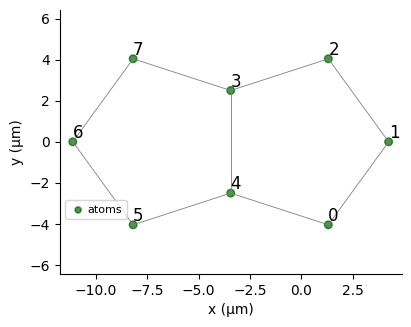

/usr/local/lib/python3.13/dist-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


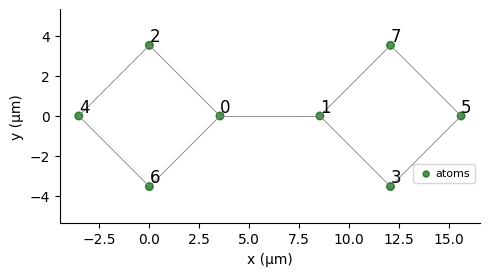

In [51]:
pent_dict = nx.get_node_attributes(G_pentagones, 'pos')
square_sict = nx.get_node_attributes(G_square, 'pos')

reg_pentagone = Register(pent_dict)
reg_pentagone.draw(
    blockade_radius=5.5
)

reg_square = Register(square_sict)
reg_square.draw(
    blockade_radius=5.5
)

# Question 4

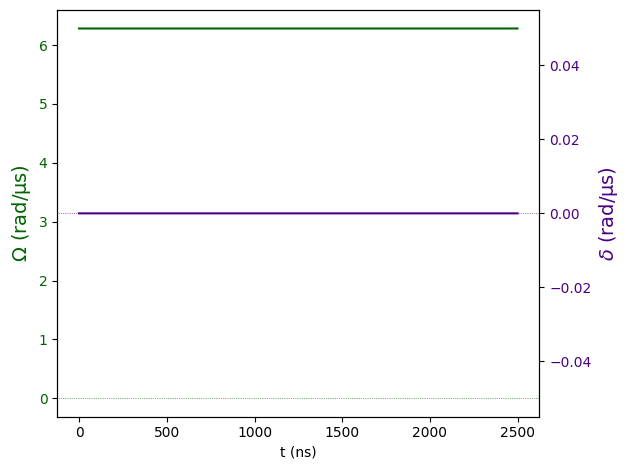

In [66]:
constant_pulse = Pulse.ConstantPulse(amplitude=2*np.pi, detuning=0, phase=0, duration=2500)

constant_pulse.draw()

# Question 5

Channel: ch0
t: 0 | Initial targets: 0, 1, 2, 3, 4, 5, 6, 7 | Phase Reference: 0.0 
t: 0->2500 | Pulse(Amp=6.28 rad/µs, Detuning=0 rad/µs, Phase=0) | Targets: 0, 1, 2, 3, 4, 5, 6, 7

Measured in basis: ground-rydberg
Channel: ch0
t: 0 | Initial targets: 0, 1, 2, 3, 4, 5, 6, 7 | Phase Reference: 0.0 
t: 0->2500 | Pulse(Amp=6.28 rad/µs, Detuning=0 rad/µs, Phase=0) | Targets: 0, 1, 2, 3, 4, 5, 6, 7

Measured in basis: ground-rydberg


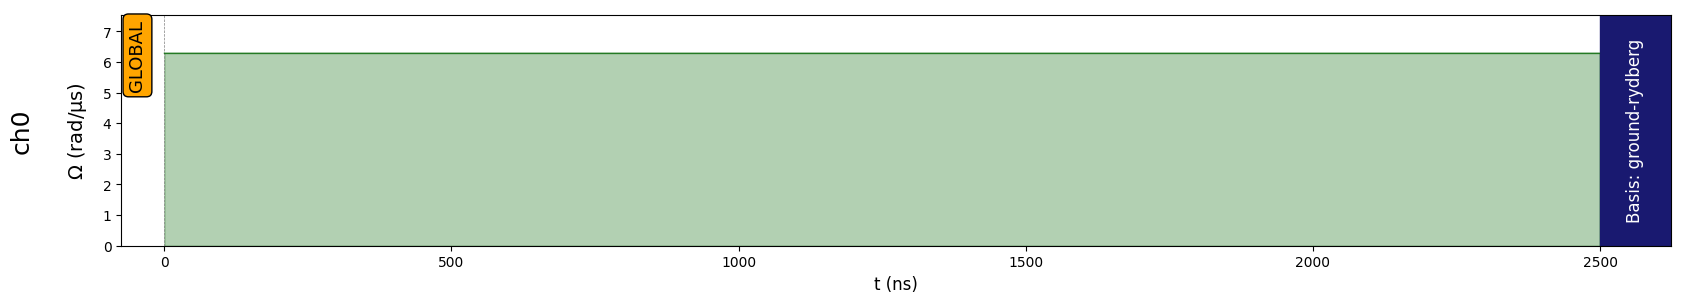

In [84]:
seq_penta = Sequence(reg_pentagone, DigitalAnalogDevice)
seq_penta.declare_channel('ch0', 'rydberg_global')
seq_penta.add(constant_pulse, 'ch0')
seq_penta.measure('ground-rydberg')

seq_square = Sequence(reg_square, DigitalAnalogDevice)
seq_square.declare_channel('ch0', 'rydberg_global')
seq_square.add(constant_pulse, 'ch0')
seq_square.measure('ground-rydberg')


print(seq_penta)
print(seq_square)
seq_penta.draw()




#Question 6

10.0%. Run time:   0.08s. Est. time left: 00:00:00:00


/tmp/ipykernel_1826/3370582414.py:3: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  res_penta = QutipBackend(seq_penta).run(progress_bar=True)


20.0%. Run time:   0.23s. Est. time left: 00:00:00:00
30.0%. Run time:   0.37s. Est. time left: 00:00:00:00
40.0%. Run time:   0.52s. Est. time left: 00:00:00:00
50.0%. Run time:   0.73s. Est. time left: 00:00:00:00
60.0%. Run time:   0.94s. Est. time left: 00:00:00:00
70.0%. Run time:   1.16s. Est. time left: 00:00:00:00
80.0%. Run time:   1.37s. Est. time left: 00:00:00:00
90.0%. Run time:   1.58s. Est. time left: 00:00:00:00
100.0%. Run time:   1.78s. Est. time left: 00:00:00:00
Total run time:   1.78s
10.0%. Run time:   0.09s. Est. time left: 00:00:00:00


/tmp/ipykernel_1826/3370582414.py:4: DeprecationWarning: 'QutipBackend' is deprecated. Please use 'pulser_simulation.QutipBackendV2' instead.
  res_square = QutipBackend(seq_square).run(progress_bar=True)


20.0%. Run time:   0.23s. Est. time left: 00:00:00:00
30.0%. Run time:   0.36s. Est. time left: 00:00:00:00
40.0%. Run time:   0.53s. Est. time left: 00:00:00:00
50.0%. Run time:   0.73s. Est. time left: 00:00:00:00
60.0%. Run time:   0.94s. Est. time left: 00:00:00:00
70.0%. Run time:   1.16s. Est. time left: 00:00:00:00
80.0%. Run time:   1.37s. Est. time left: 00:00:00:00
90.0%. Run time:   1.58s. Est. time left: 00:00:00:00
100.0%. Run time:   1.78s. Est. time left: 00:00:00:00
Total run time:   1.78s


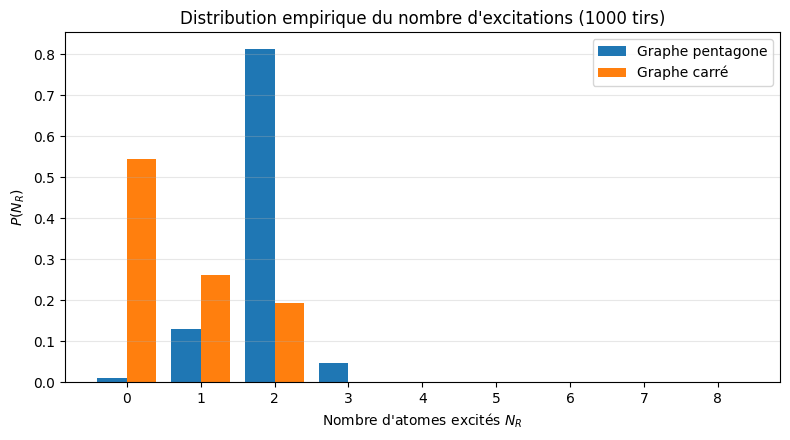

p(T) pentagone : [0.011 0.129 0.813 0.047 0.    0.    0.    0.    0.   ]
p(T) carré     : [0.544 0.262 0.194 0.    0.    0.    0.    0.    0.   ]


In [105]:
import matplotlib.pyplot as plt

res_penta = QutipBackend(seq_penta).run(progress_bar=True)
res_square = QutipBackend(seq_square).run(progress_bar=True)

counts_penta  = res_penta.sample_final_state(1000)
counts_square = res_square.sample_final_state(1000)

def distribution(counts, n_max=8):
    p = np.zeros(n_max + 1)
    for bitstring, c in counts.items():
        p[bitstring.count('1')] += c
    return p / p.sum()

p_penta = distribution(counts_penta)
p_square = distribution(counts_square)

k = np.arange(9)
w = 0.4
plt.figure(figsize=(8, 4.5))
plt.bar(k - w/2, p_penta,  width=w, label="Graphe pentagone")
plt.bar(k + w/2, p_square, width=w, label="Graphe carré")
plt.xticks(k)
plt.xlabel(r"Nombre d'atomes excités $N_R$")
plt.ylabel(r"$P(N_R)$")
plt.title("Distribution empirique du nombre d'excitations (1000 tirs)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("p(T) pentagone :", np.round(p_penta, 3))
print("p(T) carré     :", np.round(p_square, 3))

#Question 7





# Question 8

In [128]:
def entropy_shannon(P):
    P = np.asarray(P, dtype=float)
    P = P[P > 0]
    return -np.sum(P * np.log2(P))

def JSD(P, Q):
    P = np.asarray(P, dtype=float)
    Q = np.asarray(Q, dtype=float)
    M = 0.5 * (P + Q)
    return entropy_shannon(M) - 0.5 * (entropy_shannon(P) + entropy_shannon(Q))

print(JSD(p_penta, p_square))

0.42621147643605295


# Question 9